# Final Project Assignment 1

### CSCI 5612 - Machine Learning for Data Science
### Drake Miller III

In this notebook, I will gather data from the Zwicky Transient Facility (ZTF) using an API. The data will then be cleaned and converted into a pandas dataframe for future machine learning analysis.

### 1.) Gather data

In [3]:
#import relevant packages

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

#used for pulling ZTF data from API

import lsdb 
import hats
import requests
from io import StringIO
from astropy.table import Table

#clustering and PCA

from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#naive Bayes and decision trees

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [4]:
#use URL to access transient catalog, lightcurve, and image data 

#transients_path = ("s3://ipac-irsa-ztf/ztf/enhanced/dr24/objects/hats") #transient catalog data
lightcurves_path = ("s3://ipac-irsa-ztf/ztf/enhanced/dr24/lc/hats") #transient lightcurve data
#images_path = ("https://irsa.ipac.caltech.edu/ibe/search/ztf/products/sci") #image data

#transients = lsdb.read_hats(transients_path)
#transients.columns

lightcurves = lsdb.read_hats(lightcurves_path)
lightcurves = lsdb.open_catalog(lightcurves_path)
print(lightcurves.npartitions)
print(lightcurves.columns)

12485
Index(['objectid', 'filterid', 'objra', 'objdec', 'lightcurve'], dtype='object')


In [5]:
#examine one lightcurve data point

lc_sample = lightcurves.head(3)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

In [6]:
lc_sample["lightcurve"].iloc[2]

,hmjd,mag,magerr,clrcoeff,catflags
0,58384.36177,18.126699,0.030027,-0.070279,0
1,58427.33331,18.178541,0.031089,-0.069309,0
...,...,...,...,...,...
43,60235.35815,18.143246,0.030360,-0.091248,0
44,60238.35307,18.151487,0.030528,-0.070024,0


### Data Cleaning

In [7]:
#create a function that cleans the data and extracts useful lightcurve info

def lc_data(lc):

    ### lc = light curve input data ###

    #clean data
    lc = lc.sort_values('hmjd') #sort chronologically by observation time
    good_data = (np.isfinite(lc['hmjd']) & np.isfinite(lc['mag']) & np.isfinite(lc['magerr']) & (lc['catflags'] == 0)) #choose finite, non-nan, quality observations from the data to keep
    clean_lc = lc[good_data]

    if len(clean_lc) <= 1:
        return None #do not use lightcurves with only one observation

    #extract useful quantities
    time = clean_lc['hmjd'].to_numpy() #observation time in units of Heliocentric Modified Julian Days
    time = (time - time[0])*(24)*(60)*(60) #observations time in units of seconds, starting from t=0s
    mag = clean_lc['mag'].to_numpy() #apparent magnitude
    magerr = clean_lc['magerr'].to_numpy() #apparent magnitude uncertainty
    flux = 10**(-0.4*(mag+48.60)) #flux in erg/cm^2
    fluxerr = (np.log(10)/2.5)*flux*magerr #propagated flux uncertainty in erg/cm^2

    #convert data into useful ML dataset features
    features = {} #empty dictionary that will hold features for the final project

    dt = np.diff(time) #time difference
    features['n_obs'] = len(mag) #number of observations for this transient
    features['total_time'] = np.max(time) - np.min(time) #total observation time of this transient in seconds
    features['med_cadence'] = np.median(dt) #median observation time cadence in seconds
    features['min_cadence'] = np.min(dt) #minimum observation time in seconds
    features['max_cadence'] = np.max(dt) #maximum observation time in seconds

    features['mean_mag'] = np.mean(mag) #mean magnitude
    features['median_mag'] = np.median(mag) #median magnitude
    features['mean_magerr'] = np.mean(magerr) #mean magnitude uncertainty
    features['median_magerr'] = np.median(magerr) #median magnitude uncertainty
    features['std_mag'] = np.std(mag) #standard deviation of magnitude
    features['min_mag'] = np.min(mag) #minimum magnitude
    features['max_mag'] = np.max(mag) #maximum magnitude
    features['mag_amplitude'] = np.max(mag) - np.min(mag) #full amplitude of observation
    
    features['mean_flux'] = np.mean(flux) #mean flux
    features['median_flux'] = np.median(flux) #median flux
    features['mean_fluxerr'] = np.mean(fluxerr) #mean flux uncertainty
    features['median_fluxerr'] = np.median(fluxerr) #median flux uncertainty
    features['std_flux'] = np.std(flux) #standard deviation of flux
    features['min_flux'] = np.min(flux) #minimum magnitude
    features['min_flux_ind'] = np.argmin(flux) #minimum flux index
    features['max_flux'] = np.max(flux) #maximum flux
    features['max_flux_ind'] = np.argmax(flux) #maximum flux index
    features['flux_amplitude'] = np.max(flux) - np.min(flux) #full amplitude of observation
    features['flux_ratio'] = np.max(flux)/np.min(flux) #flux ratio
    features['med_flux_ratio'] = np.median(np.max(flux)/np.min(flux)) #median flux ratio
    features['frac_flux'] = (np.max(flux) - np.min(flux))/np.median(flux) #fractional flux increase

    peak_ind = np.argmax(flux) #index where the flux reaches a maximum (global)
    peak_flux = flux[peak_ind] #maximum flux (global)
    peak_time = time[peak_ind] #time of maximum flux (global)
    baseline_flux = np.median(flux) #estimate baseline flux with median, which should be dominated by quiescent times
    amplitude = peak_flux - baseline_flux #define max amplitude relative to baseline
    f10 = baseline_flux + 0.1*amplitude #define lower flux threshold
    above = flux > f10 #find where the flux exceeds the lower threshold
    
    start_ind = peak_ind
    while start_ind > 0 and above[start_ind - 1]:
        start_ind -= 1 #start at global flux peak and work backwards until flux is 10% of the peak amplitude
    
    end_ind = peak_ind
    while end_ind < len(flux)-1 and above[end_ind + 1]:
        end_ind += 1 #start at the global flux peak and work forwards until flux is 10% of the peak amplitude
    
    t10_rise = np.nan #initialize times
    t10_decay = np.nan #initialize times
    
    if start_ind > 0 and end_ind < len(flux)-1: #only calculate times when both sides are fully observed
        i = start_ind - 1 #10% rise crossing
        t10_rise = time[i] + (f10-flux[i])/(flux[i+1]-flux[i])*(time[i+1]-time[i]) #10% rise time = start time --> where flux = 10% max amplitude
        i = end_ind #10% decay crossing
        t10_decay = time[i] + (f10-flux[i])/(flux[i+1]-flux[i])*(time[i+1]-time[i]) #10% decay time = start time --> where flux = 10% max amplitude
    
    rise_time = peak_time - t10_rise #characteristic rise time
    decay_time = t10_decay - peak_time #characteristic decay time
    time_ratio = (decay_time/rise_time if np.isfinite(rise_time) and rise_time > 0 else np.nan) #calculate time ratio
    
    features['peak_flux'] = peak_flux
    features['peak_time'] = peak_time
    features['peak_flux_amplitude'] = amplitude
    features['rise_time'] = rise_time
    features['decay_time'] = decay_time
    features['decay_rise_ratio'] = time_ratio
    
    return features

In [8]:
#define a function that extracts the lightcurve features via partitions

def process_partition(df):

    ### df = pandas partition filled with lightcurves ###

    filter_map = {1: 'g', 2: 'r', 3: 'i'} #g, r, i, photometric bands
    rows = []
    for _, row in df.iterrows():
        features = lc_data(row['lightcurve']) #extract lightcurve features
        if features is None: 
            continue #for lightcurves without enough data

        features = {'objectid': row['objectid'], 'ra': row['objra'], 'dec': row['objdec'], 'filterid': row['filterid'], 
                    'band': filter_map.get(row['filterid']), **features} #add objectid, ra, dec, and filterid to the existing features dict
        rows.append(features)

    return pd.DataFrame(rows)

In [9]:
#test the functions using a sample of lightcurve data

test = lightcurves.head(10)
test_features = process_partition(test)
print(test_features.shape)
print(test_features.dtypes)
test_features.head()

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

(8, 37)
objectid              int64
ra                  float64
                     ...   
decay_time          float64
decay_rise_ratio    float64
Length: 37, dtype: object


,objectid,ra,dec,filterid,band,n_obs,total_time,med_cadence,min_cadence,max_cadence,...,flux_amplitude,flux_ratio,med_flux_ratio,frac_flux,peak_flux,peak_time,peak_flux_amplitude,rise_time,decay_time,decay_rise_ratio
0,402214400001930,45.001633,0.003649,2,r,3,6.393993e+07,3.196996e+07,5867593.344,5.807234e+07,...,1.403373e-28,2.920402,2.920402,1.706722,2.134144e-28,5.867593e+06,1.311881e-28,5.280834e+06,4.885771e+07,9.251894
1,1447107200003291,44.996162,0.005613,1,g,43,1.601848e+08,1.256878e+05,38.880,6.333766e+07,...,3.495426e-28,1.187904,1.187904,0.174901,2.209760e-27,6.367735e+07,2.112474e-28,3.014377e+01,5.162189e+05,17125.223402
2,1447207200005775,44.996151,0.005617,2,r,49,1.613918e+08,1.714271e+05,38.016,7.092415e+07,...,4.027609e-28,1.124226,1.124226,0.116275,3.644916e-27,3.722814e+07,1.810559e-28,3.559946e+01,9.401264e+05,26408.445145
3,402314400002005,44.996151,0.005628,3,i,90,1.205309e+08,3.458143e+05,79038.720,2.153258e+07,...,4.963380e-28,1.130534,1.130534,0.121411,4.298699e-27,2.445885e+07,2.106051e-28,2.241208e+05,1.843758e+05,0.822662
4,402214400001906,44.996151,0.005630,2,r,429,2.288630e+08,1.732247e+05,77.760,1.601017e+07,...,6.848890e-28,1.220233,1.220233,0.200403,3.794720e-27,7.488982e+07,3.771599e-28,8.242582e+04,5.143381e+04,0.624001


In [8]:
#compute the original sky positions data

original_sky = (lightcurves.partitions[:10][['objectid', 'objra', 'objdec']].compute())

Computing Catalog:   0%|          | 0/20 [00:00<?, ?it/s]

KeyboardInterrupt: 

/var/folders/3k/d657z_jx759g2yllmb7nn_tc0000gn/T/ipykernel_3585/1466625835.py:79: RuntimeWarning: invalid value encountered in scalar divide
  t10_decay = time[i] + (f10-flux[i])/(flux[i+1]-flux[i])*(time[i+1]-time[i]) #10% decay time = start time --> where flux = 10% max amplitude


In [10]:
#run this algorithm for the entire DR24 survey using Dask/LSDB

meta = test_features.iloc[0:0].copy() #use the test as metadata for Dask
ml_data = lightcurves.map_partitions(process_partition, meta=meta) #extracted features, but NOT computed yet (lazy); DO NOT COMPUTE

In [12]:
#choose 10 partitions to compute

ml_sample_inds = np.sort(np.random.choice(lightcurves.npartitions, 10, replace=False)) #10 random partitions, keep it to < 30 or so (about 1 hour of computing time)
ml_sample = ml_data.partitions[ml_sample_inds]
start = time.time() #start timer
ml_df = ml_sample.compute() #compute 10-partition sample
elapsed = time.time() - start #compute total elapsed time of computation

print(f"10 partitions: {elapsed:.1f} seconds") #print total time in seconds
print(f"Rows produced: {len(ml_df)}") #print length of dataframe

Computing Catalog:   0%|          | 0/20 [00:00<?, ?it/s]

10 partitions: 2804.2 seconds
Rows produced: 3582067


### Exploratory Data Analysis

In [ ]:
#compute the original sky positions data

original_sky = (lightcurves.partitions[:10][['objectid', 'objra', 'objdec']].compute())

In [43]:
len(og_ra)

3541887

In [39]:
#plot dec vs. ra on the sky for the original 10 partitions without cleaning

og_sky_data = original_sky.drop_duplicates(subset='objectid') #drop duplicate data

# convert RA and Dec from degrees to radians
og_ra = np.radians(og_sky_data['objra'].values)
og_dec = np.radians(og_sky_data['objdec'].values)

og_ra = -og_ra #reverse ra for convention

fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='mollweide') #all-sky projection
ax1.scatter(og_ra, og_dec, s=2, alpha=0.5)
ax1.grid(True)
ax1.set_title('All-Sky Coverage (Original Data)')

ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(og_ra, og_dec, s=2, alpha=0.5)
ax2.set_xlabel('Right Ascension ' + r'$(^{\circ})$')
ax2.set_ylabel('Declination ' + r'$(^{\circ})$')
ax2.set_title('RA vs. Dec (Original Data)')

fig.tight_layout()
fig.savefig('og_sky_pos.png')

NameError: name 'original_sky' is not defined

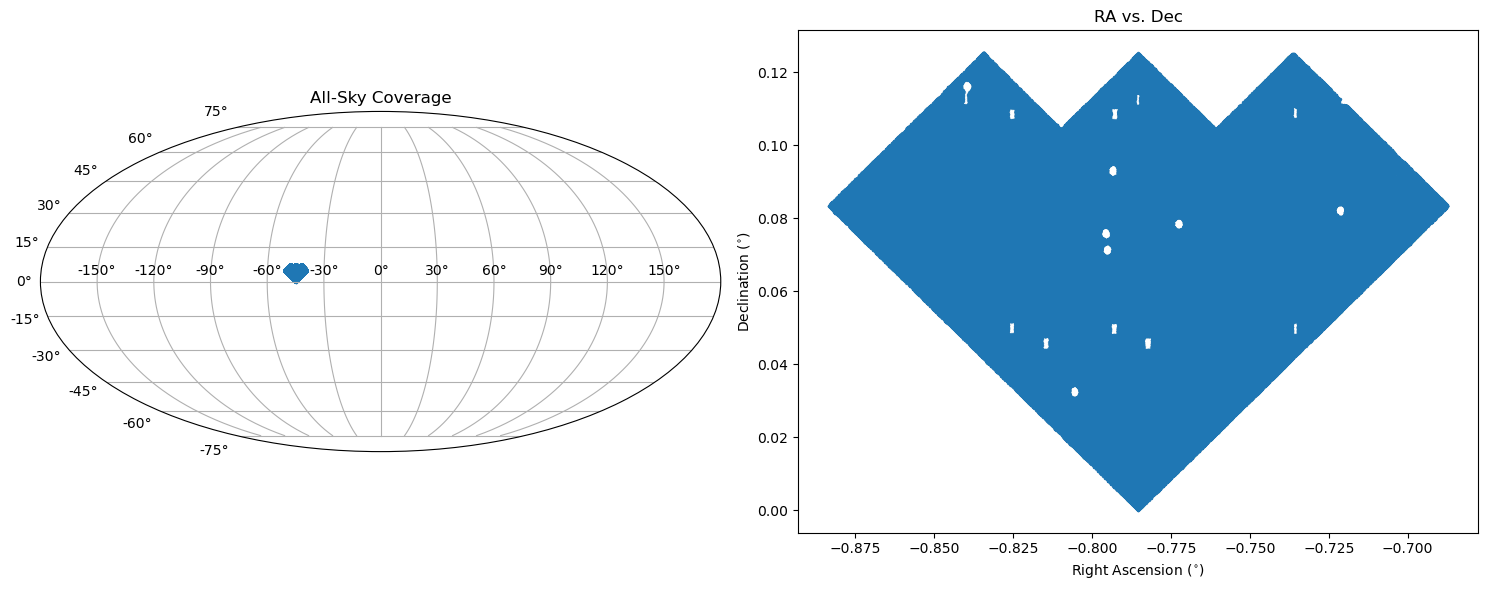

In [144]:
#plot dec vs. ra on the sky for the 10 cleaned partitions

sky_data = ml_df.drop_duplicates(subset='objectid') #drop duplicate data

# convert RA and Dec from degrees to radians
ra = np.radians(sky_data['ra'].values)
dec = np.radians(sky_data['dec'].values)

ra = -ra #reverse ra for convention

fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='mollweide') #all-sky projection
ax1.scatter(ra, dec, s=2, alpha=0.5)
ax1.grid(True)
ax1.set_title('All-Sky Coverage')

ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(ra, dec, s=2, alpha=0.5)
ax2.set_xlabel('Right Ascension ' + r'$(^{\circ})$')
ax2.set_ylabel('Declination ' + r'$(^{\circ})$')
ax2.set_title('RA vs. Dec')

fig.tight_layout()
fig.savefig('sky_pos.png')

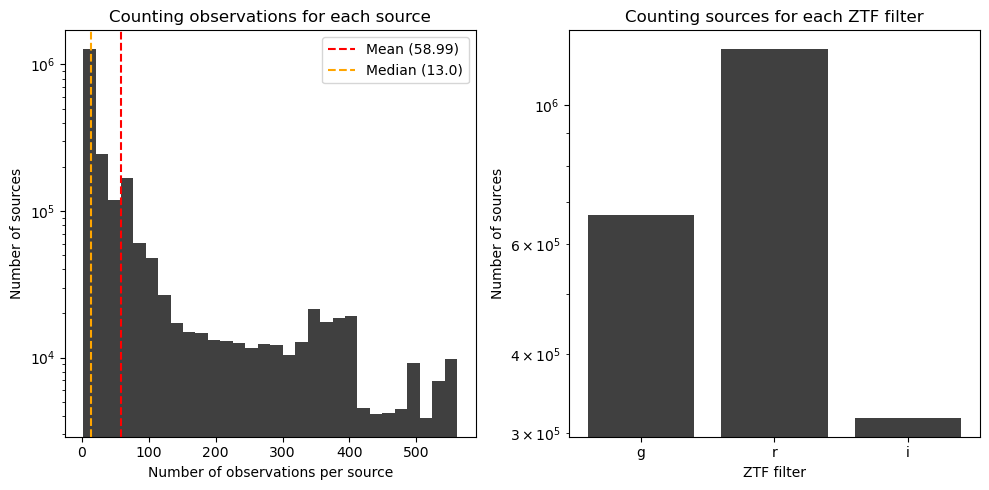

In [40]:
#plot a histogram showing the number of observations for each source

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))

ax1.hist(ml_df['n_obs'], bins=30, color='black', alpha=0.75)
ax1.axvline(np.mean(ml_df['n_obs']), color='red', linestyle='--', label='Mean (' + str(round(np.mean(ml_df['n_obs']), 2)) + ')')
ax1.axvline(np.median(ml_df['n_obs']), color='orange', linestyle='--', label='Median (' + str(round(np.median(ml_df['n_obs']), 2)) + ')')
ax1.set_xlabel('Number of observations per source')
ax1.set_ylabel('Number of sources')
ax1.set_yscale('log')
ax1.set_title('Counting observations for each source')
ax1.legend(loc='best')

filter_counts = ml_df['filterid'].value_counts()
ax2.bar(filter_counts.index, filter_counts.values, color='black', alpha=0.75)
ax2.set_xlabel('ZTF filter')
ax2.set_xticks([1, 2, 3], ['g', 'r', 'i'])
ax2.set_ylabel('Number of sources')
ax2.set_yscale('log')
ax2.set_title('Counting sources for each ZTF filter')

fig.tight_layout()
fig.savefig('n_obs_hist.png')

In [41]:
#pull a few sources from partition 0

example = lightcurves.partitions[0].head(20)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

In [42]:
#find which lightcurves have more observations and choose one

example['n_obs'] = example['lightcurve'].apply(len)
example[['objectid', 'filterid', 'n_obs']].sort_values('n_obs', ascending=False)
example = example.loc[example['n_obs'].idxmax()]

example_id = example['objectid']
lc = example['lightcurve']

In [43]:
#clean data the same as before

lc = lc.sort_values('hmjd')
good_data = (np.isfinite(lc['hmjd']) & np.isfinite(lc['mag']) & np.isfinite(lc['magerr']) & (lc['catflags'] == 0))
lc_clean = lc[good_data]

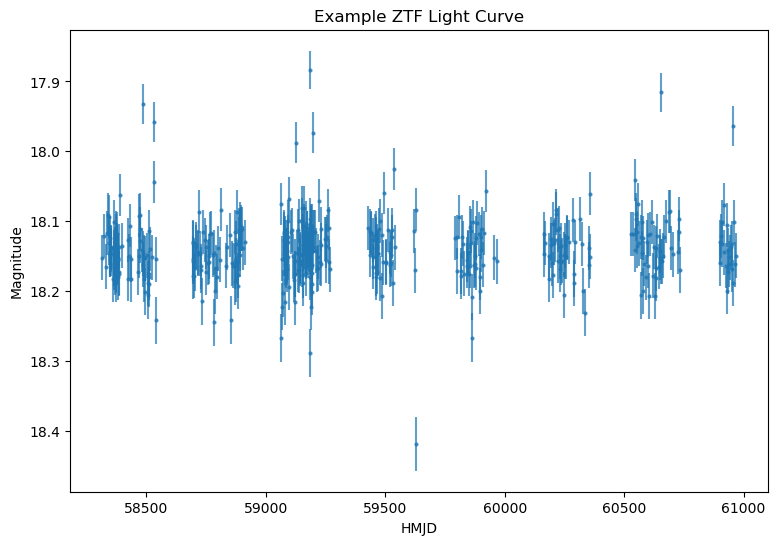

In [44]:
#plot the example light curve

plt.figure(figsize=(9, 6))
plt.errorbar(lc_clean['hmjd'], lc_clean['mag'], yerr=lc_clean['magerr'], fmt='.', markersize=4, alpha=0.7)
plt.xlabel('HMJD')
plt.ylabel('Magnitude')
plt.title(f'Example ZTF Light Curve')
plt.gca().invert_yaxis() #magnitudes are inverted brightness
plt.savefig('ex_lightcurve.png')

In [49]:
#extract and flatten the rise and decay times

#rise_times = np.concatenate(ml_df['rise_time'].values)
#decay_times = np.concatenate(ml_df['decay_time'].values)
ml_df['decay_time']

0         4.885771e+07
1         5.162189e+05
              ...     
157803    1.525517e+05
157804             NaN
Name: decay_time, Length: 2212201, dtype: float64

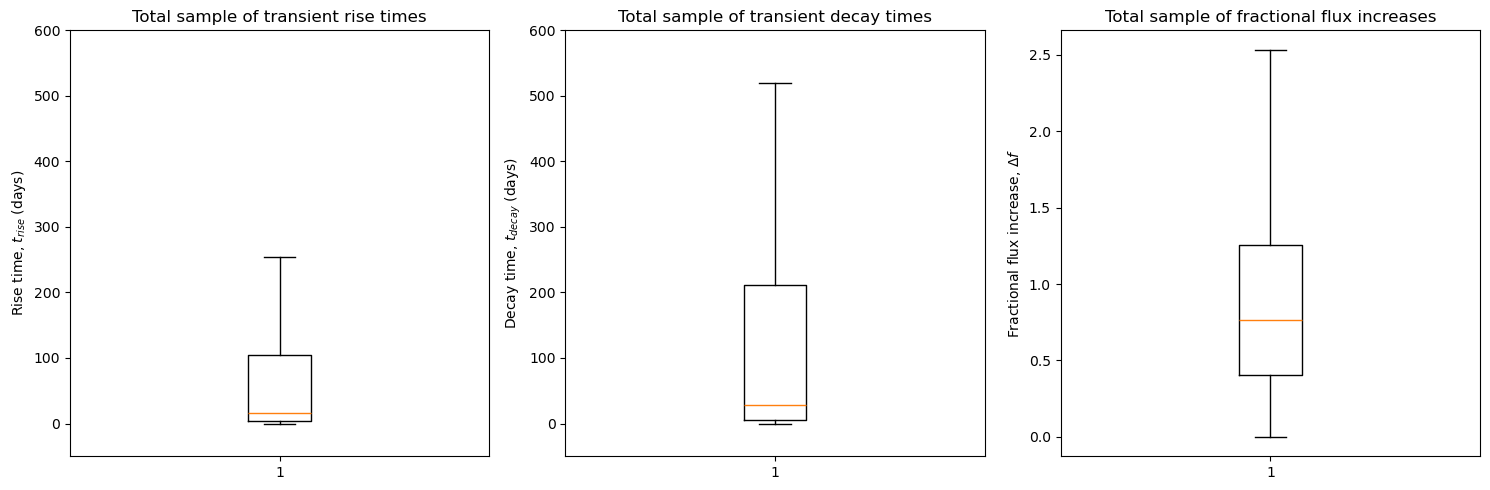

In [57]:
#create boxplots for the total sample of rise and decay times

rise_time_arr = np.array(ml_df['rise_time'])
rise_time_arr = rise_time_arr[~np.isnan(rise_time_arr)]
decay_time_arr = np.array(ml_df['decay_time'])
decay_time_arr = decay_time_arr[~np.isnan(decay_time_arr)]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))

ax1.boxplot(rise_time_arr/86400, showfliers=False)
ax1.set_ylabel('Rise time, ' + r'$t_{rise}$' + ' (days)')
ax1.set_ylim(-50, 600)
ax1.set_title('Total sample of transient rise times')

ax2.boxplot(decay_time_arr/86400, showfliers=False)
ax2.set_ylabel('Decay time, ' + r'$t_{decay}$' + ' (days)')
ax2.set_ylim(-50, 600)
ax2.set_title('Total sample of transient decay times')

ax3.boxplot(ml_df['frac_flux'], showfliers=False)
ax3.set_ylabel('Fractional flux increase, ' + r'$\Delta f$')
ax3.set_title('Total sample of fractional flux increases')

fig.tight_layout()
fig.savefig('transient_boxplots.png')

### Clustering

In [133]:
#select the transient rise/decay times, the flux amplitude, the flux amplitude, and the flux ratio

transient_data = ml_df[['rise_time', 'decay_time']] #4-dimensional data structure
transient_data

#define arrays of quantities and apply a condition to remove NANs

nan_condition = np.isfinite(np.array(ml_df['rise_time'])) & np.isfinite(np.array(ml_df['decay_time'])) #remove rows with NANs

rise_time = np.array(ml_df['rise_time'])[nan_condition]/(60*60*24)
decay_time = np.array(ml_df['decay_time'])[nan_condition]/(60*60*24)
time_ratio = np.array(ml_df['decay_rise_ratio'])[nan_condition]
flux_amplitude = np.array(ml_df['peak_flux_amplitude'])[nan_condition]

In [134]:
transient_data[nan_condition]

,rise_time,decay_time
0,5.280834e+06,4.885771e+07
1,3.014377e+01,5.162189e+05
...,...,...
157799,4.789196e+07,1.711719e+06
157803,1.116913e+05,1.525517e+05


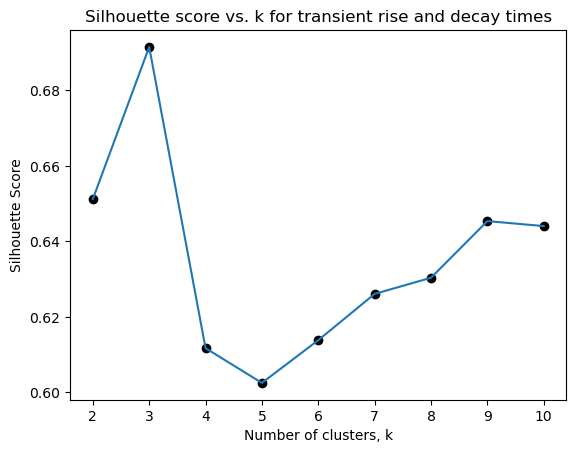

In [111]:
#perform the silhouette method to determine an optimal number of clusters k 

standard_data = StandardScaler().fit_transform((ml_df[['rise_time', 'decay_time']]/(60*60*24))[nan_condition][:20000]) #standardize the data based on all transient rise/decay times and flux amplitude/ratio

ks = np.linspace(2, 10, 9) #array of k values from 1-9
scores = [] #empty list that will hold the silhouette scores
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0) #perform k-means clustering 10 times with random initializations
    km.fit(standard_data) #scale to the data
    scores.append(silhouette_score(standard_data, km.labels_)) #silhouette scores

#print the best k value, which has the maximum silhouette score
optimal_k = np.argmax(scores) #index of the maximum value

#plot the silhouette scores vs. k

plt.figure()
plt.plot(ks, np.array(scores))
plt.scatter(ks, np.array(scores), color='black')
plt.xlabel('Number of clusters, k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette score vs. k for transient rise and decay times')
plt.savefig('silhouette.png')

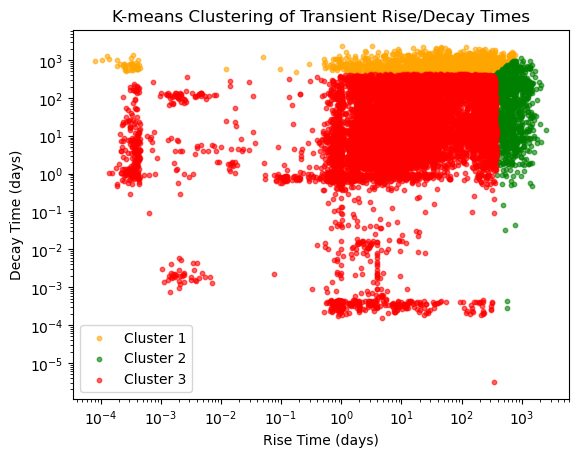

In [115]:
#perform k-means clustering for the rise time and decay time data

km = KMeans(n_clusters=3, n_init=10, random_state=0) #choose k=3 from the silhouette method above
labels = km.fit_predict(standard_data)

colors = ['orange', 'green', 'red']
for i in range(3):
    mask = labels == i
    plt.scatter(rise_time[:20000][mask], decay_time[:20000][mask], color=colors[i % len(colors)], s=10, alpha=0.6, label=f'Cluster {i+1}')
plt.xlabel('Rise Time (days)')
plt.xscale('log')
plt.ylabel('Decay Time (days)')
plt.yscale('log')
plt.title('K-means Clustering of Transient Rise/Decay Times')
plt.legend()
plt.savefig('kmeans_clusters.png')

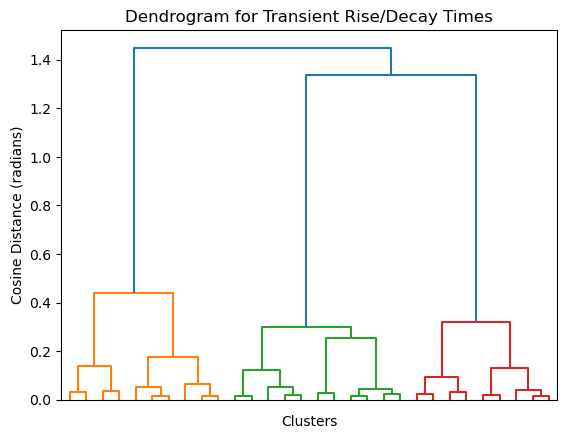

In [116]:
#perform hierarchical clustering for the rise time and decay time data

distance_measure = linkage(standard_data, method='average', metric='cosine') # can also use "single" or "complete" for cosine similarity

dendrogram(distance_measure, truncate_mode='lastp', p=30, show_leaf_counts=False)
plt.xlabel('Clusters')
plt.ylabel('Cosine Distance (radians)')
plt.title('Dendrogram for Transient Rise/Decay Times')
plt.savefig('dendrogram.png')

labels = fcluster(distance_measure, t=0.5, criterion='distance')

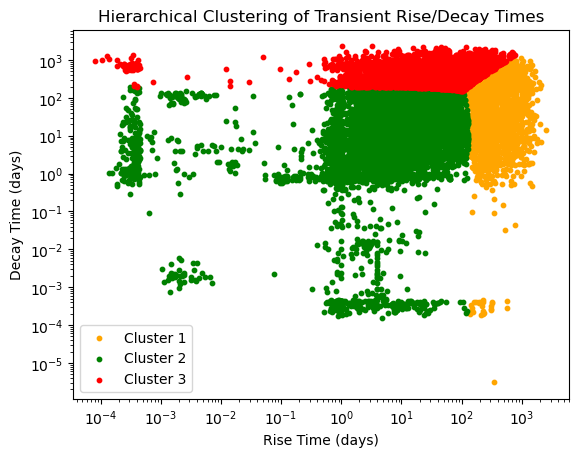

In [117]:
#visualize the clusters

colors = ['orange', 'green', 'red']
unique_labels = np.unique(labels)
cluster_colors = {label: colors[i % len(colors)] for i, label in enumerate(unique_labels)}

for label in unique_labels:
    mask = labels == label
    plt.scatter(rise_time[:20000][mask], decay_time[:20000][mask], color=cluster_colors[label], s=10, label=f'Cluster {label}')

plt.xlabel('Rise Time (days)')
plt.xscale('log')
plt.ylabel('Decay Time (days)')
plt.yscale('log')
plt.title('Hierarchical Clustering of Transient Rise/Decay Times')
plt.legend(loc='best')
plt.savefig('hierarchical_clusters.png')

### Principal Component Analysis

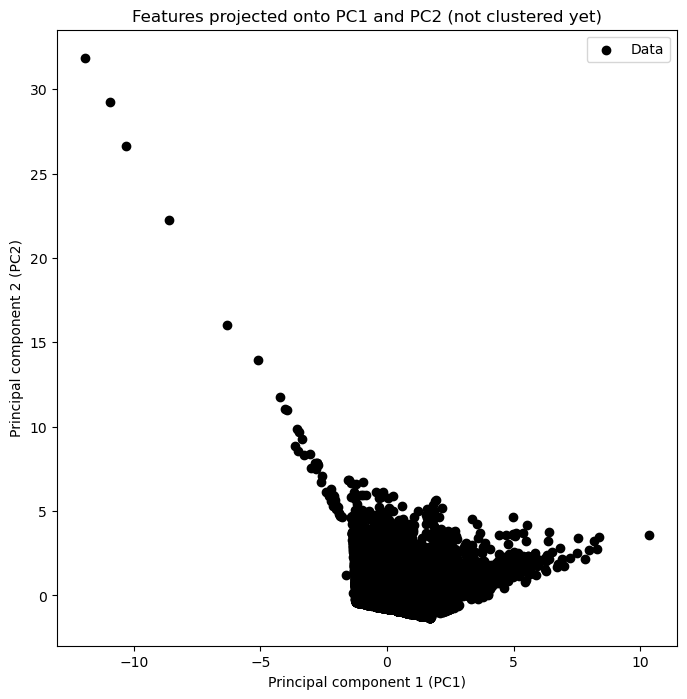

In [129]:
#use PCA to reduce the dimensions of the dataset, and visualize the final clusters in 2D

standard_data = StandardScaler().fit_transform((ml_df[['peak_time', 'rise_time', 'decay_time', 'decay_rise_ratio']]/(60*60*24))[nan_condition][:20000]) #standardize the data based on all transient temporal data

pca = PCA(n_components=4) #reduce the data to 4 dimensions; these four dimensions will hold the four largest components of the variance
pc_data = pca.fit_transform(standard_data) #data rescaled to PC1 and PC2

#plot the resulting clusters in 2D

plt.figure(figsize=(8,8))
plt.scatter(pc_data[:,0], pc_data[:,1], color='black', label='Data')
plt.xlabel('Principal component 1 (PC1)')
plt.ylabel('Principal component 2 (PC2)')
plt.title('Features projected onto PC1 and PC2 (not clustered yet)')
plt.legend(loc='best')

### Naive Bayes

In [22]:
#import relevant packages for Naive Bayes supervised learning

from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [20]:
#extract the data

transient_data = ml_df[['rise_time', 'decay_time']] #2-dimensional data structure
labels = ml_df['band'] #photometric band

mask = np.isfinite(transient_data['rise_time']) & np.isfinite(transient_data['decay_time']) #remove NaNs
transient_data = transient_data[mask]
labels = labels[mask]

In [24]:
#split the data into training and testing datasets

X_train, X_test, y_train, y_test = train_test_split(transient_data, labels, test_size=0.2, random_state=42, stratify=labels) #split into training and testing datasets
vec = KBinsDiscretizer(n_bins=10, encode='onehot', strategy='quantile', quantile_method='averaged_inverted_cdf') #discretize continuous numerical features into bins
X_train_scaled = vec.fit_transform(X_train) #scale to the training data
X_test_scaled = vec.transform(X_test) #scale to the testing data

In [30]:
#perform multinomial NB on the transient rise/decay times

model = MultinomialNB(alpha=1.0) #train Multinomial Naive Bayes with Laplace smoothing
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled) #predict photometric bands
print("Accuracy:", accuracy_score(y_test, y_pred)) #evaluate model

Accuracy: 0.5098521887004449


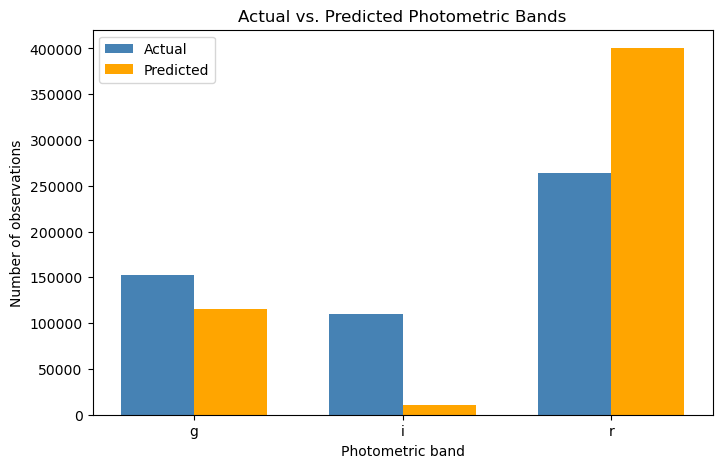

In [33]:
#make a histogram of predicted photometric bands

# Compare actual and predicted photometric bands

bands = np.unique(np.concatenate([y_test.to_numpy(), y_pred]))

actual_counts = [np.sum(y_test == band) for band in bands]
pred_counts = [np.sum(y_pred == band) for band in bands]

x = np.arange(len(bands))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, actual_counts, width,
        label='Actual', color='steelblue')

plt.bar(x + width/2, pred_counts, width,
        label='Predicted', color='orange')

plt.xticks(x, bands)
plt.xlabel('Photometric band')
plt.ylabel('Number of observations')
plt.title('Actual vs. Predicted Photometric Bands')
plt.legend()
plt.savefig('predicted_bands.png')

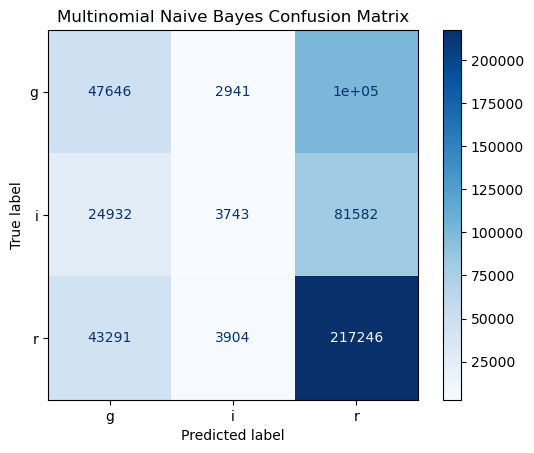

In [34]:
#compute and plot the confusion matrix for the NB classifier

cm = confusion_matrix(y_test, y_pred) #calculate confusion matrix
cm_plot = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_) #plot confusion matrix
cm_plot.plot(cmap='Blues')
plt.title('Multinomial Naive Bayes Confusion Matrix')
plt.savefig('NB_confusion_matrix.png')

### Decision Trees

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [70]:
#use the same data (testing, training, etc.) as in NB above

#decision tree classifier using GINI impurity

tree = DecisionTreeClassifier(criterion='gini', max_depth=3, min_samples_leaf=10, random_state=42) #train decision tree classifier
tree.fit(X_train, y_train) #run the training data through the tree
y_pred = tree.predict(X_test) #predict photometric bands

print("Gini Accuracy:", accuracy_score(y_test, y_pred)) #compute accuracy

Gini Accuracy: 0.5018922427536782


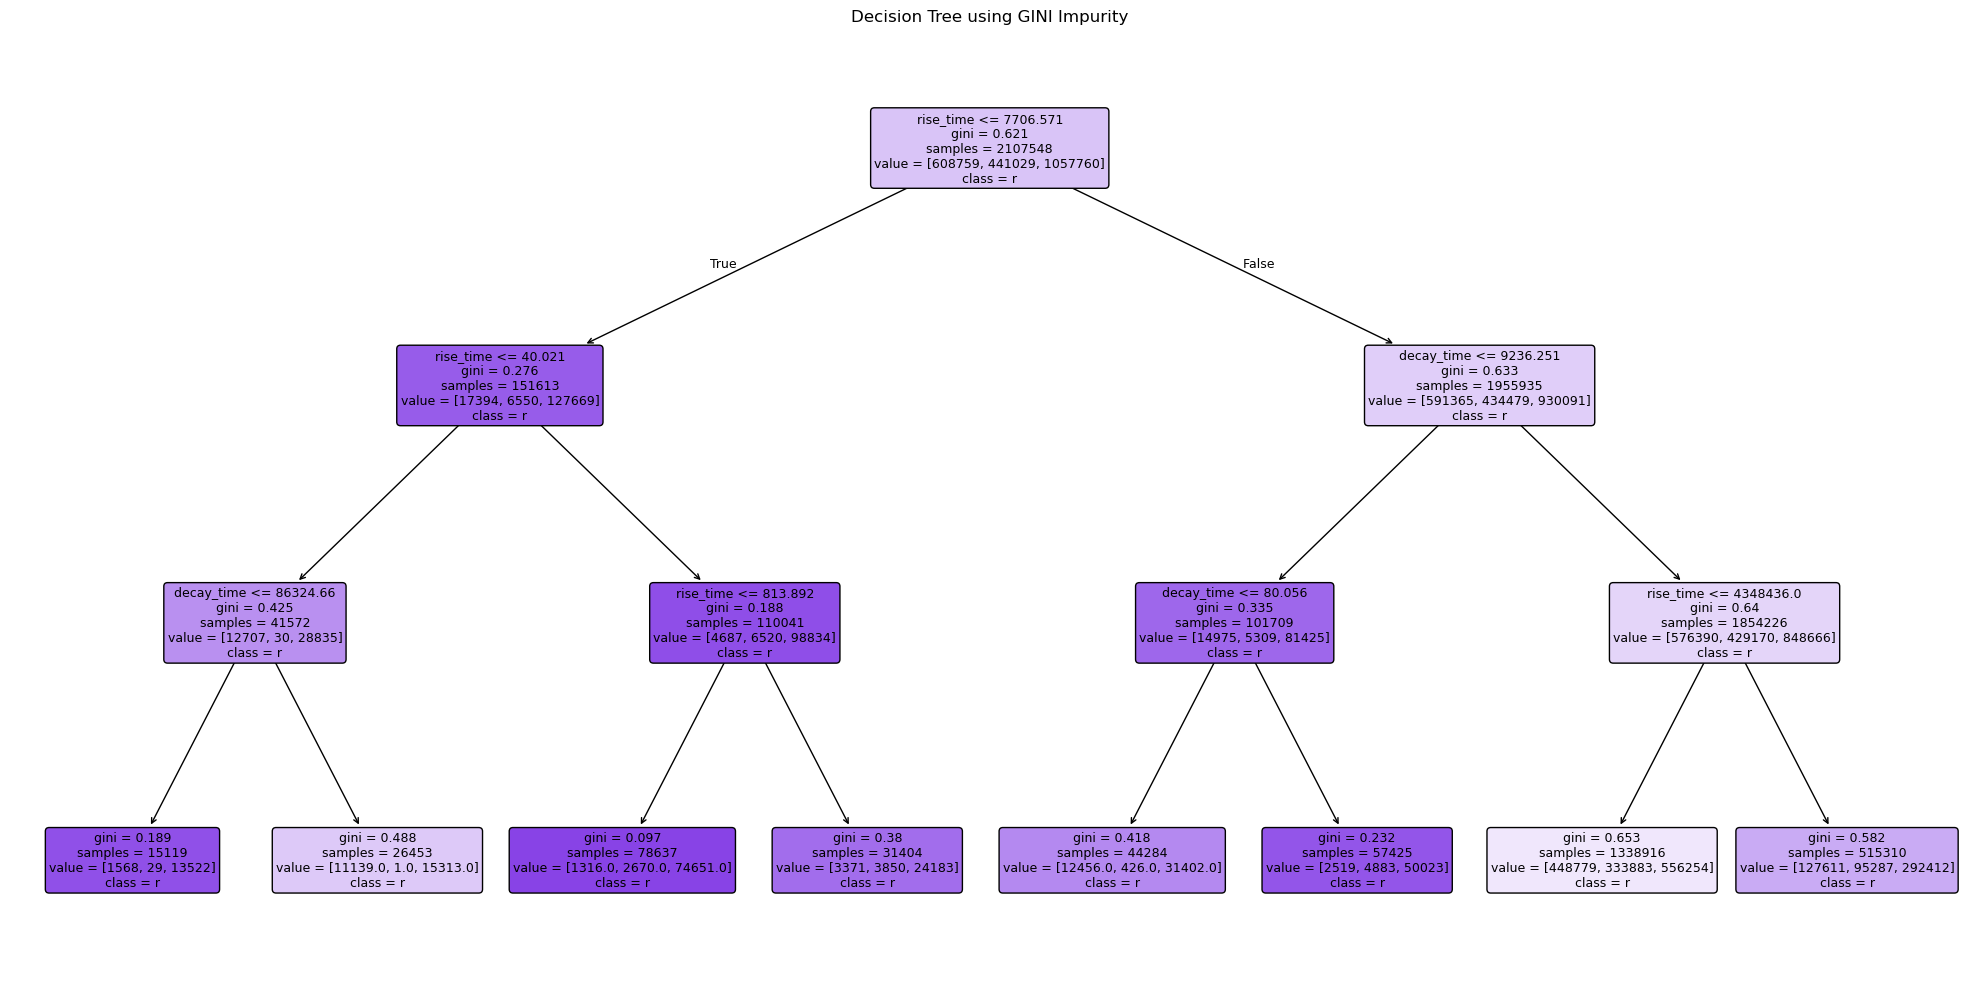

In [71]:
#visualize the decision tree

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=transient_data.columns, class_names=tree.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree using GINI Impurity')
plt.tight_layout()
plt.savefig('gini_tree.png')

In [74]:
#decision tree classifier using entropy

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=10, random_state=42) #train decision tree classifier
tree.fit(X_train, y_train) #run the training data through the tree
y_pred = tree.predict(X_test) #predict photometric bands

print("Entropy Accuracy:", accuracy_score(y_test, y_pred)) #compute accuracy

Entropy Accuracy: 0.5018922427536782


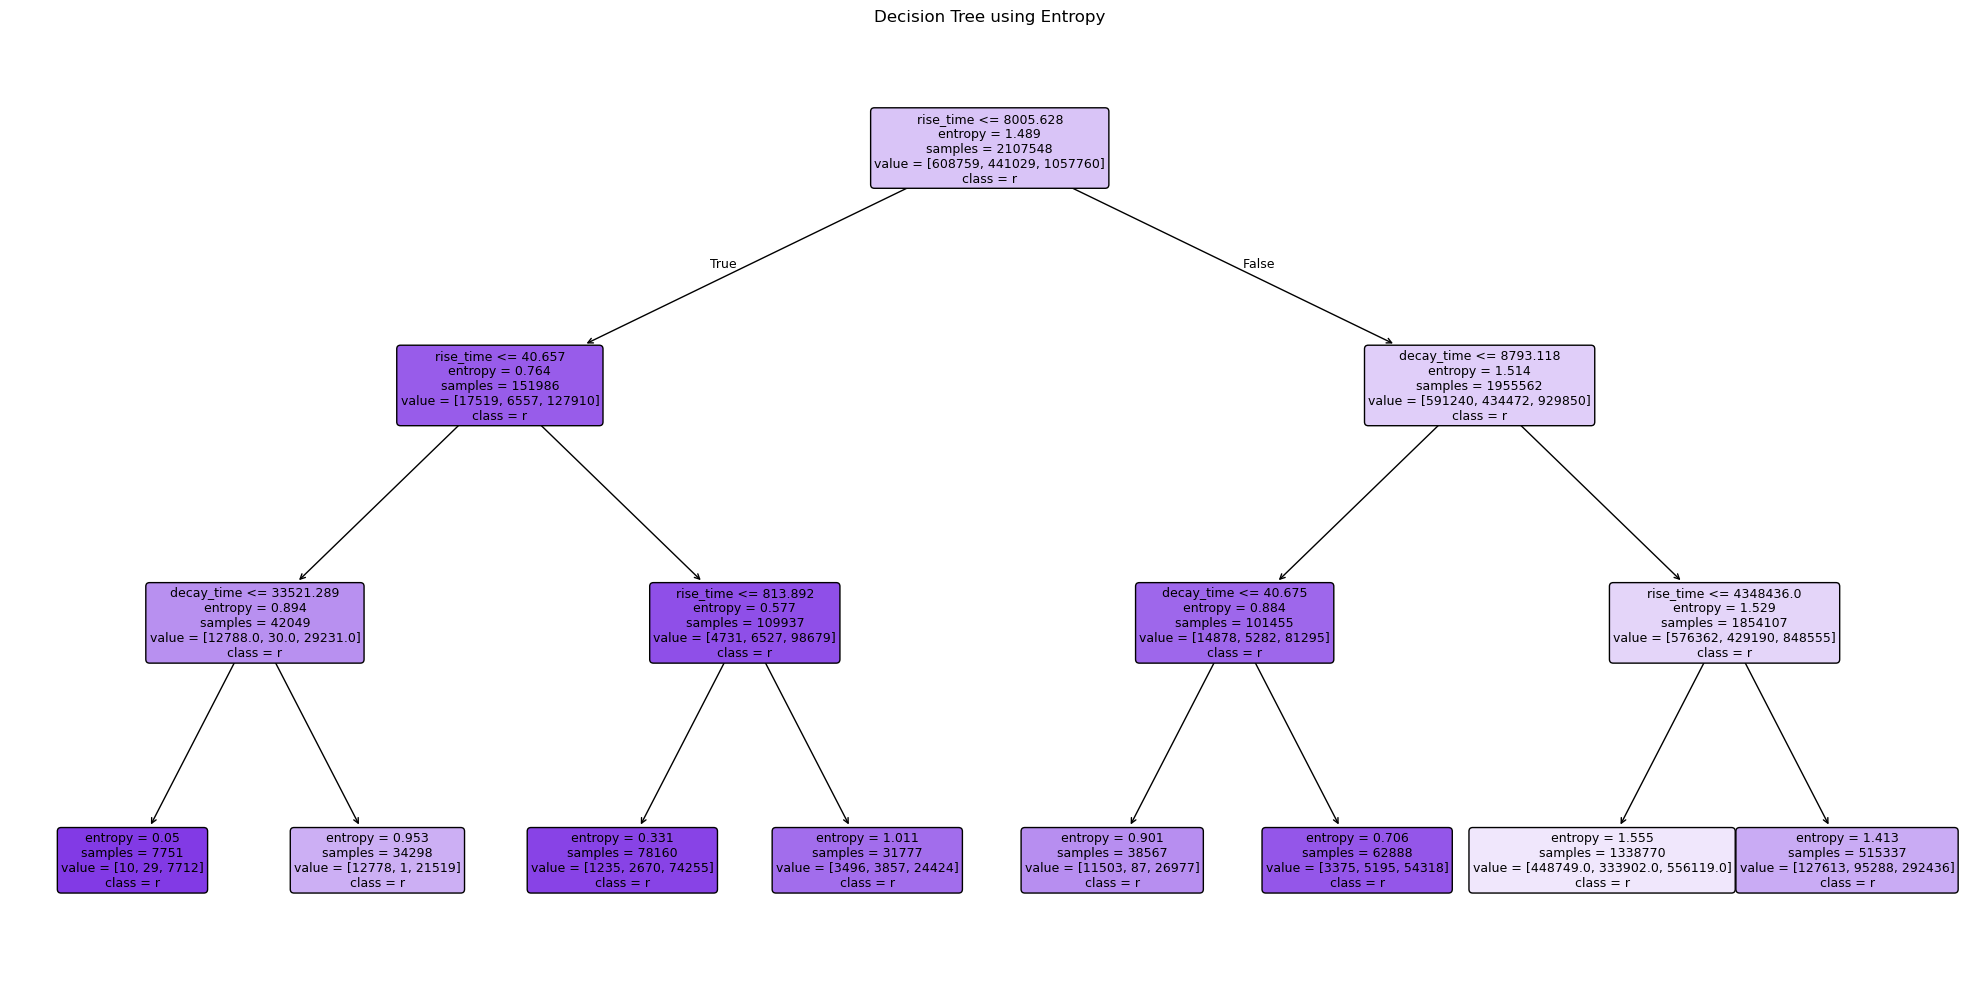

In [75]:
#visualize the decision tree

plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=transient_data.columns, class_names=tree.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree using Entropy')
plt.tight_layout()
plt.savefig('entropy_tree.png')

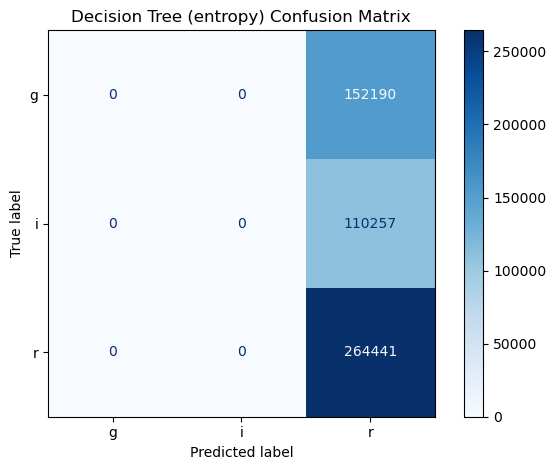

In [76]:
#compute and plot the confusion matrix for the NB classifier

cm = confusion_matrix(y_test, y_pred, labels=tree.classes_)
cm_plot = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=tree.classes_) #plot confusion matrix
cm_plot.plot(cmap='Blues')
plt.title('Decision Tree (entropy) Confusion Matrix')
plt.tight_layout()
plt.savefig('dectree_confusion_matrix.png')

In [44]:
#decision tree classifier using entropy

accuracies = [] #empty list of accuracies
for i in range(1, 50):
    tree = DecisionTreeClassifier(criterion='entropy', max_depth=i, min_samples_leaf=10, random_state=42) #train decision tree classifier
    tree.fit(X_train, y_train) #run the training data through the tree
    yi_pred = tree.predict(X_test) #predict photometric bands
    accuracies.append(accuracy_score(y_test, yi_pred))

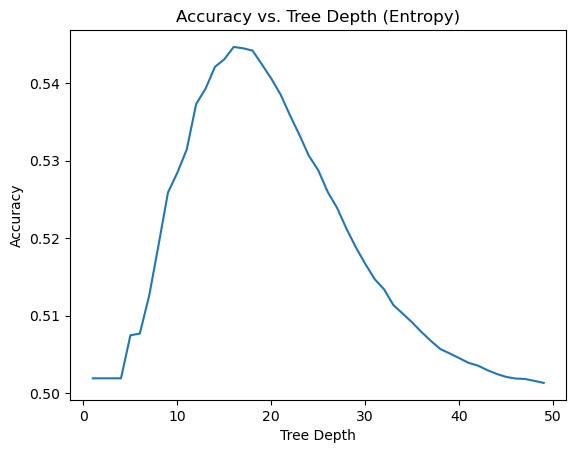

In [72]:
#plot the accuracy vs. tree depth

tree_depth = np.arange(1, 50, 1)

plt.figure()
plt.plot(tree_depth, accuracies)
plt.xlabel('Tree Depth')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Tree Depth (Entropy)')
plt.savefig('accuracy_depth.png')

### Image data (for later)

In [9]:
#use URL to access transient image data

params = {"FORMAT": "csv"}

response = requests.get(images_path, params=params)
response.raise_for_status()

images = pd.read_csv(StringIO(response.text))

images.head()

,"<?xml version=""1.0"" encoding=""utf-8""?>"
0,"<VOTABLE version=""1.3"" xmlns:xsi=""http://www.w..."
1,<DESCRIPTION>Caltech/IPAC-IRSA Image Backend...
2,"<RESOURCE type=""results"">"
3,"<INFO name=""QUERY_STATUS"" value=""ERROR"">Us..."
4,</RESOURCE>


In [13]:
#using a sample of data, create an astropy table of ra/dec sky positions to use for image cutouts

sample = transients.head(1000) #take only the first 1000 objects
sky_positions = Table() #create an astropy table
sky_positions["ra"] = sample["ra"] #create and populate the right ascension column
sky_positions["dec"] = sample["dec"] #create and populate the declination column

sky_positions

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

ra,dec
float64,float64
44.6067206,1.2436736
44.6066019,1.2436912
44.6067067,1.2443114
44.6060791,1.2461088
44.6010665,1.2464787
44.6040686,1.2454352
44.6058883,1.2470843
44.614772,1.2416056
44.6148192,1.2417164
